In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sn
import plotly.express as px
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


In [ ]:
df.shape

(32581, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
print(df.isnull().sum())
print()
print()
print(df['loan_status'].unique()) # Classification problem -> class imbalance prob

print(df['loan_status'].value_counts())

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


[1 0]
loan_status
0    25473
1     7108
Name: count, dtype: int64


In [ ]:
df.duplicated().sum()

np.int64(165)

<Axes: xlabel='count', ylabel='loan_status'>

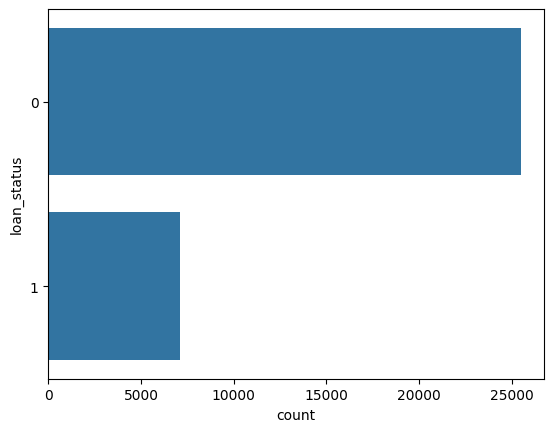

In [ ]:
sn.countplot(y = 'loan_status' , data = df)

In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns

for i in numerical_cols:
    fig = px.histogram(x = df[i])
    fig.update_layout(title_text = i, template = 'plotly_dark')
    fig.show()

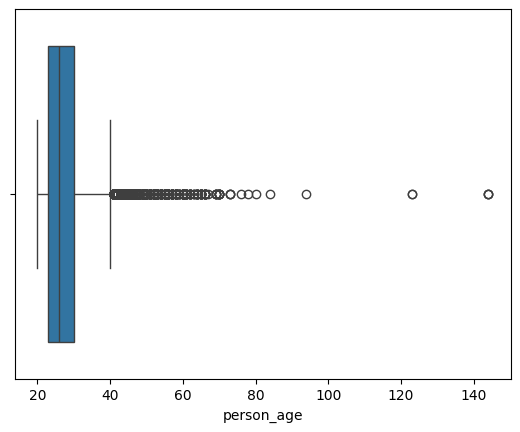

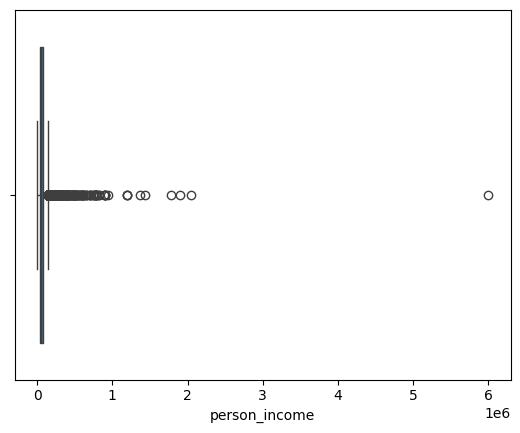

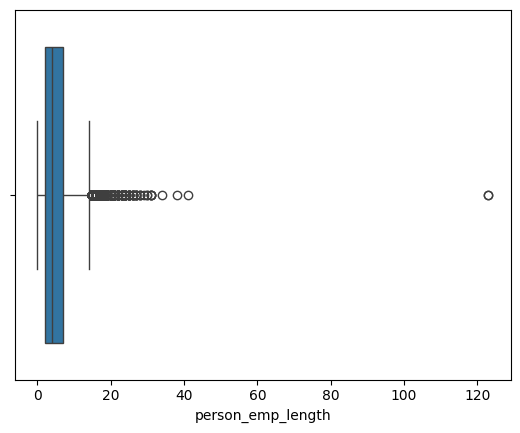

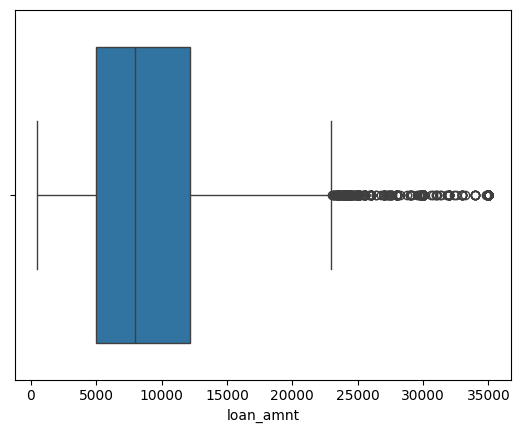

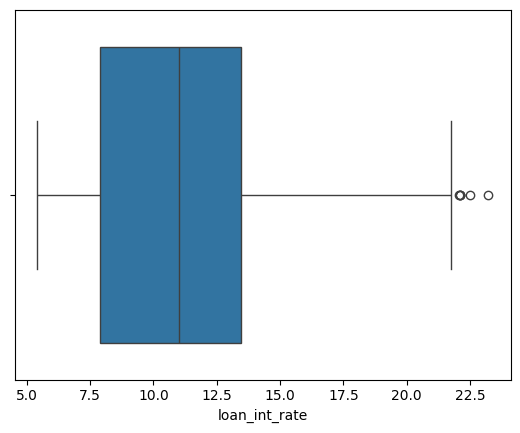

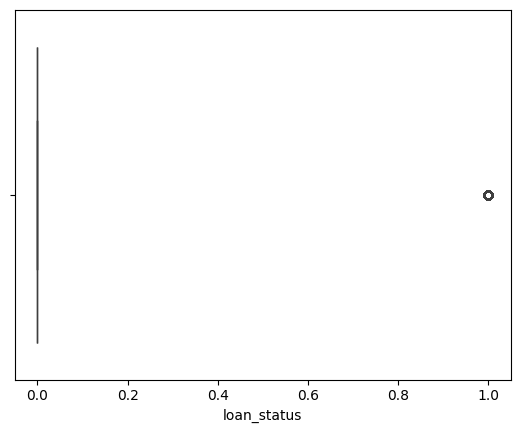

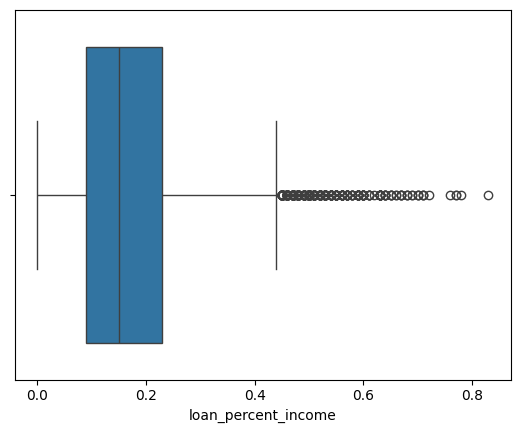

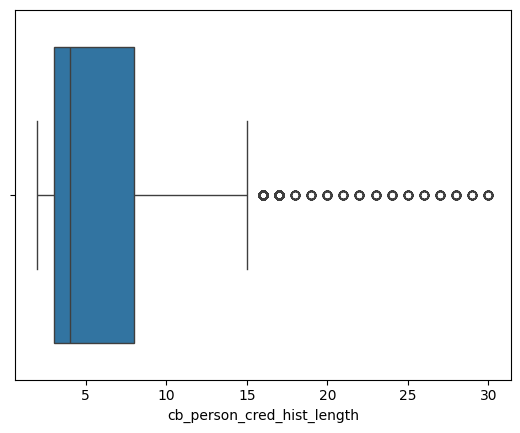

In [ ]:
for i in numerical_cols:
    sn.boxplot(x = df[i])
    plt.show()

In [ ]:
print((df['person_age'] > 100).sum())
print()
print((df['person_emp_length'] > 60).sum())

5

2


<Axes: >

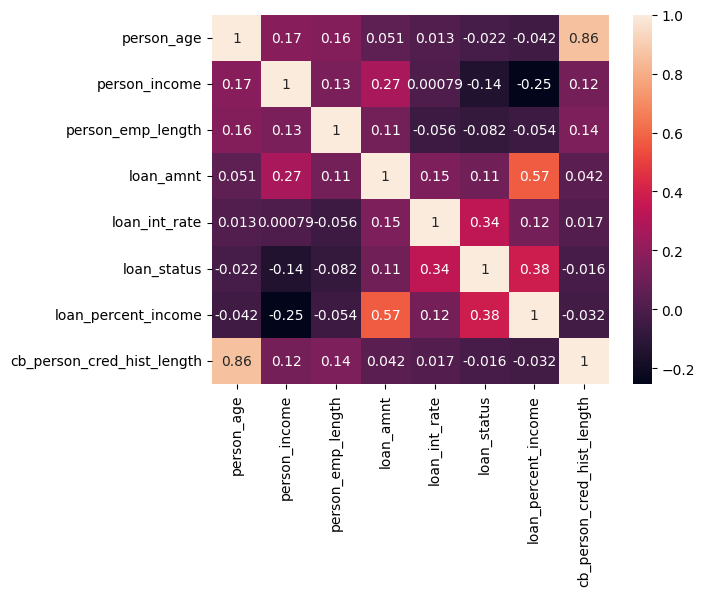

In [ ]:
sn.heatmap(df.corr(numeric_only = True) , annot = True)

3. Data Validation & Outlier Handling

- Here we clean the data properly.
- We remove duplicate rows.
- We remove rows with an impossible age or work experience.
- We remove rows with zero or negative income and loan amount.
- We check if the interest rate looks realistic.
- We also flag rows where numbers don't add up correctly.

In [ ]:
df_copy = df.copy()

print(f"original rows in df: {df_copy.shape[0]}")

# Remove the duplicated row
df_copy.drop_duplicates(inplace = True)
print(f'rows after removing duplicates: {df_copy.shape[0]}')

# Remove ages below 18 or below 100
df_copy  = df_copy[df_copy['person_age'] >= 18]
df_copy  = df_copy[df_copy['person_age'] <= 100]

# Remove employment length greater than age or extream outliers(<60)
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

# Keep rows with valid positive loan amounts and positive income
df_copy = df_copy[(df_copy['loan_amnt'] > 0) & (df_copy['person_income'] > 0)]

# check if the interest rate looks realistic
print('loan interest rate range from (min : 5.42 to max : 23.22) ')

original rows in df: 32581
rows after removing duplicates: 32416
loan interest rate range from (min : 5.42 to max : 23.22) 


4. Features, Target & Train-Test Split
- We separate the data into input features and the target.
- The target is whether the applicant defaulted or not.
- We split the data into a training part and a testing part.
- The model learns from the training part only.

In [ ]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (31522, 11)
Target shape: (31522,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , OneHotEncoder , LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # use stratify when the target column is categorical
# codition is target column must not be balanced [1,0]

5. Handle Class Imbalance
- Very few people actually default in this data.
- If we ignore this, the model may just favor the - majority class.
- We give more importance to the minority classduring training.
- This helps the model actually learn to spot - defaulters.

In [ ]:
print(y_train.value_counts())

loan_status
0    19772
1     5445
Name: count, dtype: int64


In [ ]:
# class - Weights
neg , pos = np.bincount(y_train)
scale_weights = neg/pos
print(scale_weights)

3.6312213039485766


6. Data Preprocessing — Pipelines & Column Transformer

- Raw data is not ready for a model directly.
- We need to prepare numeric and text columns differently.
- We will build a Pipeline for each model.
- We will use ColumnTransformer to apply different steps to different columns.
>  Preprocessing for Logistic Regression
- Fill missing numeric values.
- Scale numeric values, since this model is sensitive to scale.
- Convert category columns into numbers using one-hot encoding.

In [ ]:
numeric_cols = df_copy.select_dtypes(include = np.number).columns
categorical_cols = df_copy.select_dtypes(include = 'object').columns


In [ ]:
# Redefine numeric_cols to exclude the target column 'loan_status'
numeric_cols = df_copy.drop('loan_status', axis=1).select_dtypes(include=np.number).columns
categorical_cols = df_copy.select_dtypes(include='object').columns

In [ ]:
# Logistic reg > impute + SCALE Numeric , impute + One_hot Encoding

from sklearn.impute import SimpleImputer


preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

In [ ]:
# Xgboost > impute numeric cols only (No Scaling) + impute + One_hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

In [ ]:
# Random Forest > impute numeric cols only (No Scaling) + impute + One_hot Encoding

preprocessor_rf = ColumnTransformer(
    transformers = [
        # Pipeline for numeric cols
        ('num' , Pipeline([
            ('imputer' , SimpleImputer(strategy = 'median'))
        ]) , numeric_cols),

        # Pipeline for Categorical Cols
        ('cat' , Pipeline([
            ('imputer' , SimpleImputer(strategy = 'constant' , fill_value = 'Missing')),
            ('onehot' , OneHotEncoder(handle_unknown = 'ignore'))
        ]), categorical_cols)
    ]
)

7. Evaluation Helper Function
- We build one common function to check any model's performance.
- It will show accuracy, precision, recall, F1 score, and more.
- It will also show a confusion matrix and a precision-recall curve.

In [ ]:
from sklearn.metrics import classification_report , confusion_matrix , precision_score , recall_score , f1_score , accuracy_score , precision_recall_curve
# Have to evaluate the logistic & XgBoost model
def evalute_model(model_name , model , x_test , y_test , threshold = None ):
    y_pred  = model.predict(x_test)
    y_pred_prob = model.predict_proba(x_test)[:,1]

    # Metrices
    accuracy = accuracy_score(y_test , y_pred)
    precision = precision_score(y_test , y_pred)
    recall = recall_score(y_test , y_pred)
    f1 = f1_score(y_test , y_pred)

    # Confusion Matrix
    cm  = confusion_matrix(y_test , y_pred)
    class_report = classification_report(y_test , y_pred)

    print(f"{model_name} Metrics:")
    if threshold is not None: # Only print threshold if provided
        print(f"Threshold: {threshold}")
    print(f"Accuracy : {accuracy:.2f}")
    print(f"Precision : {precision:.2f}")
    print(f"Recall : {recall:.2f}")
    print(f"F1 : {f1:.2f}")
    print()
    print(f"{model_name} Classification Report:")
    print(class_report)

    # plotting the confusion matrix
    sn.heatmap(cm , annot = True ,fmt = 'd')  # format-> decimal
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()


    # Plotting Roc-Auc curve
    precisions , recalls , threshold  = precision_recall_curve(y_test , y_pred)
    plt.plot(threshold , precisions[:-1] , 'b--' , label = 'Precision')
    plt.plot(threshold , recalls[:-1] , 'g-' , label = 'Recall')
    plt.xlabel('Threshold')
    plt.legend(loc = 'upper left')


8. Stratified Cross-Validation
- One single train-test split may not be reliable.
- We split the training data into five folds instead.
- Each fold keeps the same default vs repaid ratio.
- We check the model's score across all folds.

In [ ]:
from sklearn.model_selection import StratifiedKFold , cross_validate

cv = StratifiedKFold(n_splits= 5, random_state = 42 , shuffle = True)

scoring = {'roc_auc' : 'roc_auc' , 'accuracy' : 'accuracy' , 'precision' : 'precision' , 'recall' : 'recall' , 'f1' : 'f1'}

In [ ]:
# Logistic reg
from sklearn.linear_model import LogisticRegression

lr_cv_pipeline =  Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier' , LogisticRegression(max_iter = 1000 , class_weight = 'balanced' , random_state = 42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
from xgboost import XGBClassifier

# XGboost Model
xgb_cv_pipeline = Pipeline([
    ('preprocessor' , preprocessor_xg),
    ('classifier' ,XGBClassifier(
        n_estimators = 300,
        max_deapth = 5,
        learning_rate = 0.1 ,
        scale_pos_weight= scale_weights,
        random_state = 42
    ))
])

xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Mis...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_deapth=5,
                               max_delta_step=None, max_depth=None,
                               max_leaves=None, min_child_weight=None,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=300,
                               n_jobs=None, ...))])

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Random FORest Model
rf_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_rf),
    ('classifier' , RandomForestClassifier(n_estimators= 200 , criterion='gini' ,class_weight="balanced"))
])

rf_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200))])

In [ ]:
# 4. Run the cross-validation
for cv_name, pipe in [('Logistic Regression', lr_cv_pipeline),
                       ("XgBoost", xgb_cv_pipeline), ("Random Forest" ,rf_cv_pipeline )]:
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"=== {cv_name} ===")
    for score_name, scores in cv_res.items():
        print(f"{score_name}: {scores.mean():.4f} (+/- {scores.std():.4f})")
    print()
    print(cv_name)
    print(f"Roc-Auc {cv_res['test_roc_auc'].mean()}")
    print(f"Accuracy {cv_res['test_accuracy'].mean()}")
    print(f"Precision {cv_res['test_precision'].mean()}")
    print(f"Recall {cv_res['test_recall'].mean()}")
    print(f"F1 {cv_res['test_f1'].mean()}")
    print()

=== Logistic Regression ===
fit_time: 0.3721 (+/- 0.2056)
score_time: 0.1043 (+/- 0.0765)
test_roc_auc: 0.8705 (+/- 0.0049)
test_accuracy: 0.8116 (+/- 0.0046)
test_precision: 0.5448 (+/- 0.0087)
test_recall: 0.7781 (+/- 0.0087)
test_f1: 0.6408 (+/- 0.0036)

Logistic Regression
Roc-Auc 0.8705112830525306
Accuracy 0.8115949542892269
Precision 0.5448226008889892
Recall 0.7781450872359963
F1 0.6408013995933108

=== XgBoost ===
fit_time: 1.7564 (+/- 0.1954)
score_time: 0.1800 (+/- 0.0424)
test_roc_auc: 0.9465 (+/- 0.0045)
test_accuracy: 0.9218 (+/- 0.0015)
test_precision: 0.8361 (+/- 0.0070)
test_recall: 0.7936 (+/- 0.0132)
test_f1: 0.8142 (+/- 0.0050)

XgBoost
Roc-Auc 0.9464583882798419
Accuracy 0.9217988345431509
Precision 0.8360914107373267
Recall 0.7935720844811753
F1 0.8141637259099228

=== Random Forest ===
fit_time: 9.4728 (+/- 3.1635)
score_time: 0.4931 (+/- 0.1793)
test_roc_auc: 0.9278 (+/- 0.0047)
test_accuracy: 0.9323 (+/- 0.0027)
test_precision: 0.9703 (+/- 0.0047)
test_recall: 

In [ ]:
cv_res

{'fit_time': array([13.03061652, 12.70356107,  8.60656714,  8.5918982 ,  4.43121839]),
 'score_time': array([0.59910178, 0.78928137, 0.3599596 , 0.42111135, 0.29596114]),
 'test_roc_auc': array([0.93220157, 0.91894616, 0.92754185, 0.93063469, 0.92985205]),
 'test_accuracy': array([0.93180016, 0.92743854, 0.93396788, 0.93515764, 0.9329764 ]),
 'test_precision': array([0.96855346, 0.97131682, 0.9713217 , 0.97744361, 0.96300863]),
 'test_recall': array([0.70707071, 0.68411387, 0.71533517, 0.71625344, 0.71717172]),
 'test_f1': array([0.81740977, 0.80280172, 0.8239027 , 0.82670906, 0.82210526])}

9. Baseline Model — Logistic Regression
- We start with a simple model first.
- This becomes our benchmark to beat.
- We train it and check its score on the test data.

In [ ]:
from sklearn import base
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor' , preprocessor_lr ),
    ('classifier' , LogisticRegression(class_weight= 'balanced') ),
])
baseline_model.fit(X_train , y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

baseline Logistic model Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65

baseline Logistic model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



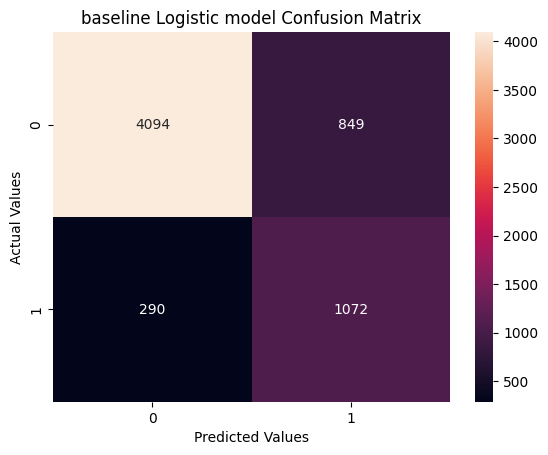

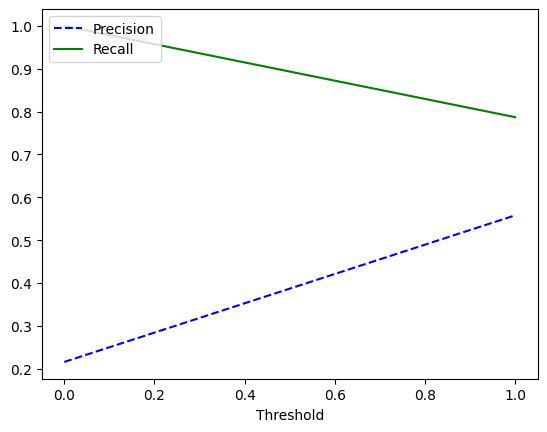

In [ ]:
# evaluate the Logistic Model

evalute_model("baseline Logistic model" , baseline_model , X_test , y_test)
#

10. XGBoost Hyperparameter Tuning
- Now we move to a stronger model, XGBoost.
- A model has many settings called hyperparameters.
- We search for the best combination of these settings.
- We use cross-validation while searching, so the result is reliable.

In [ ]:
from numpy.random import random_sample
xg_model = Pipeline([
   ( 'preprocessor' , preprocessor_xg),
   ( 'classifier' , XGBClassifier(random_state = 42 , scale_pos_weight = scale_weights , learning_rate = 0.1))
])
xg_model.fit(X_train , y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Mis...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

XGboost Metrics:
Accuracy : 0.92
Precision : 0.82
Recall : 0.79
F1 : 0.81

XGboost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



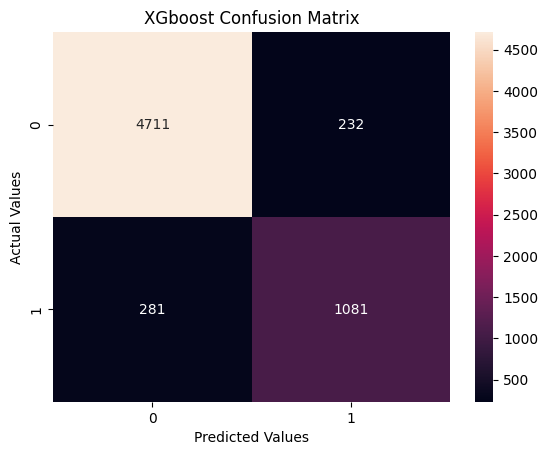

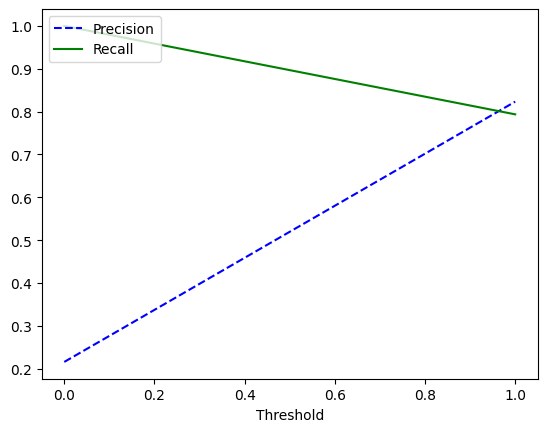

In [ ]:
evalute_model("XGboost" , xg_model , X_test , y_test)

In [ ]:
rf_model = Pipeline([
    ('preprocessor' , preprocessor_rf),
    ('classifier' , RandomForestClassifier(random_state = 42 , class_weight = 'balanced'))

])
rf_model.fit(X_train , y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

Random Forest Metrics:
Accuracy : 0.94
Precision : 0.98
Recall : 0.72
F1 : 0.83

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.98      0.72      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



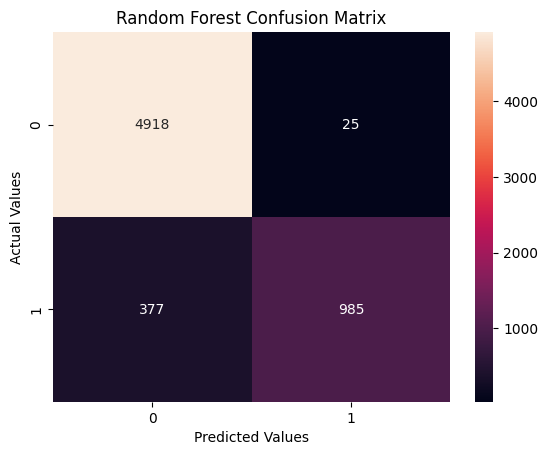

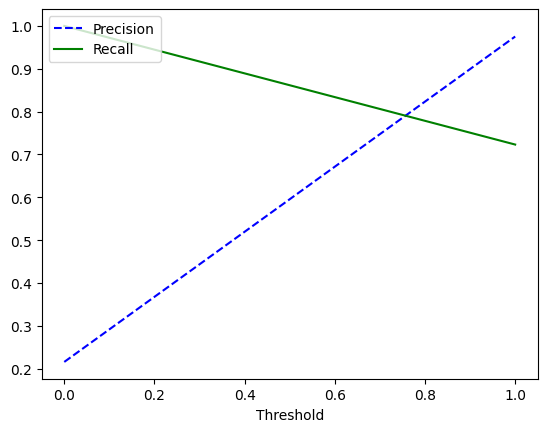

In [ ]:
evalute_model("Random Forest" , rf_model , X_test , y_test)

In [79]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform , randint
# XGboost Parameter GRid

param_grid = {
    "classifier__n_estimators" : randint(150, 600),
    "classifier__max_depth" : randint(3,9), # Corrected spelling typo from 'max_deapth' to 'max_depth'
    "classifier__learning_rate" : uniform(0.01 , 0.5),
    "classifier__subsample"  : uniform(0.6,0.4), # Row Sampling
    "classifier__colsample_bytree" : uniform(0.6,0.4) , # COlumns Sampling
    "classifier__colsample_bylevel" : uniform(0.6,0.4) ,
    "classifier__colsample_bynode" : uniform(0.6,0.4),
    "classifier__gamma" : uniform(0.1 , 0.5),
    "classifier__reg_alpha" : uniform(0.1 , 0.5),
    "classifier__reg_lambda" : uniform(0.1 , 0.5),
    "classifier__min_child_weight" : randint(1 , 10)
}

# lower Gamma -> more split of the tree -> complex tree -> higher overfitting risk
# higher Gamma -> less split of the tree -> simple tree ->  less overfitting risk

In [ ]:
# Param_grid for Random Forest Model

param_grid_rf = {
     "classifier__n_estimators" : randint(150, 600),
    "classifier__max_depth" : randint(3,9), # Corrected spelling typo from 'max_deapth' to 'max_depth'
    "classifier__min_samples_split" : randint(2,10),
    "classifier__min_samples_leaf" : randint(1,10),
    "classifier__max_features" : ["sqrt" , "log2"],
     "classifier__max_leaf_nodes" : randint(10 , 50),
     "classifier__bootstrap" : [True , False] ,
     "classifier__criterion" : ["gini" , "entropy"],
     "classifier__class_weight" : ["balanced" , "balanced_subsample"],
     "classifier__ccp_alpha" : uniform(0.001 , 0.1),
     "classifier__min_impurity_decrease" : uniform(0.001 , 0.1),
     "classifier__max_samples" : uniform(0.1 , 0.9),
     "classifier__warm_start" : [True , False],
     "classifier__random_state" : randint(1 , 100)

}


In [ ]:
random_search_xgb = RandomizedSearchCV(
    xg_model ,
    param_grid ,
    n_iter = 200 ,
    cv = cv ,
    scoring = 'average_precision' , # Changed from 'average_accuracy' to a valid metric
    n_jobs = -1 ,
    verbose = 1
)
random_search_xgb.fit(X_train , y_train)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_...
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792d1e7cf8c0>,
                                        'classifier__reg_alpha': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x792d1e8267a0>,
                                        'classifier__reg_lambda': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x792d1e825bf0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x792d1e2e5a90>},
                   scoring='average_precision', verbose=1)

In [ ]:
random_search_rf = RandomizedSearchCV(
    rf_model ,
    param_grid_rf ,
    n_iter = 200 ,
    cv = cv,
    scoring = "average_precision",
    n_jobs = -1 ,
    verbose = 1
)
random_search_rf.fit(X_train , y_train)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_...
                                        'classifier__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792d29a5a330>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792d259743e0>,
                                        'classifier__random_state': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792d1e4bb150>,
                                        'classifier__warm_start': [True,
                                                                   False]},
                   scoring='average_precision', verbose=1)

In [ ]:
print(f"Score after Performing hyperparameter Tuning {random_search_xgb.best_score_:.2f}")

Score after Performing hyperparameter Tuning 0.90


In [ ]:
print(f"Score after Performing hyperparameter Tuning {random_search_rf.best_score_:.2f}")
print(f"best Parameter of hyperparameter Tuning {random_search_rf.best_score_:.2f}")

Score after Performing hyperparameter Tuning 0.76
best Parameter of hyperparameter Tuning 0.76


In [ ]:
random_search_xgb.best_params_

{'classifier__colsample_bylevel': np.float64(0.7831980877880085),
 'classifier__colsample_bynode': np.float64(0.9167142539854112),
 'classifier__colsample_bytree': np.float64(0.9441648772458712),
 'classifier__gamma': np.float64(0.5032193607671036),
 'classifier__learning_rate': np.float64(0.14385721999914947),
 'classifier__max_depth': 5,
 'classifier__min_child_weight': 8,
 'classifier__n_estimators': 443,
 'classifier__reg_alpha': np.float64(0.35379900873563885),
 'classifier__reg_lambda': np.float64(0.5549226001265396),
 'classifier__subsample': np.float64(0.9660817653940658)}

11. Compare Both Models Side by Side
- We now compare Logistic Regression and XGBoost.
- We look at their scores together in one table.
- This helps us pick the better performing model.

Logistic model Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65

Logistic model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



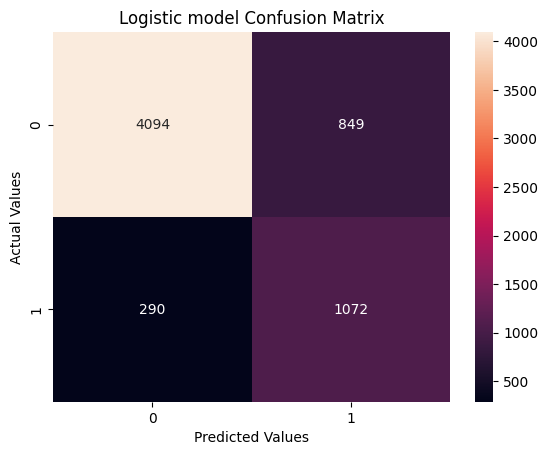

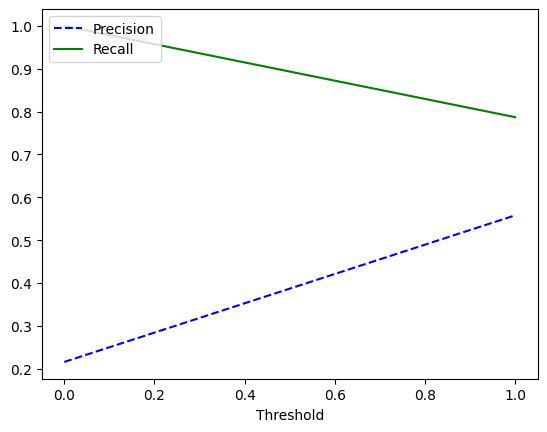

In [ ]:
evalute_model("Logistic model" , baseline_model , X_test , y_test)

XGBoost Metrics:
Accuracy : 0.92
Precision : 0.81
Recall : 0.81
F1 : 0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.81      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



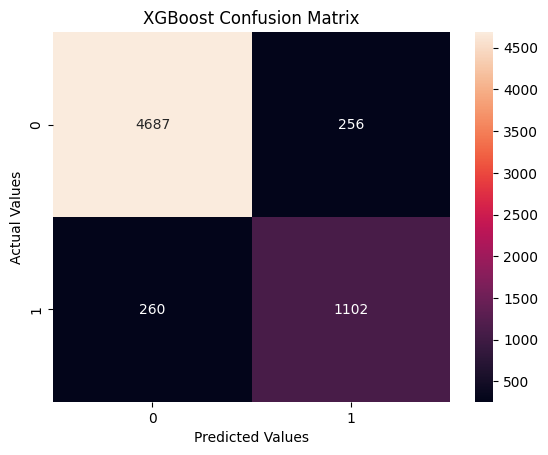

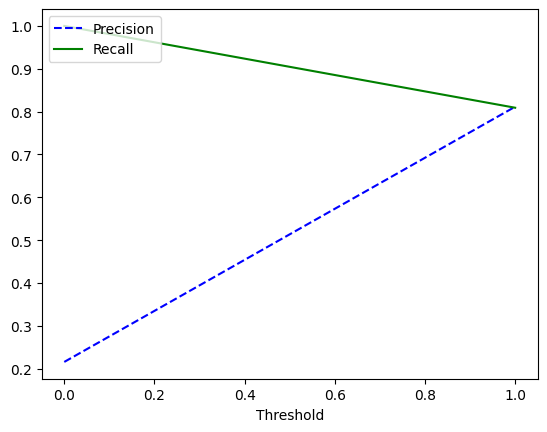

In [ ]:
# Passing the XGboost Model after Hyperparameter Tuning
evalute_model("XGBoost" , random_search_xgb.best_estimator_ , X_test , y_test)

Random Forest Metrics:
Accuracy : 0.84
Precision : 0.60
Recall : 0.78
F1 : 0.68

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.86      0.89      4943
           1       0.60      0.78      0.68      1362

    accuracy                           0.84      6305
   macro avg       0.77      0.82      0.79      6305
weighted avg       0.86      0.84      0.85      6305



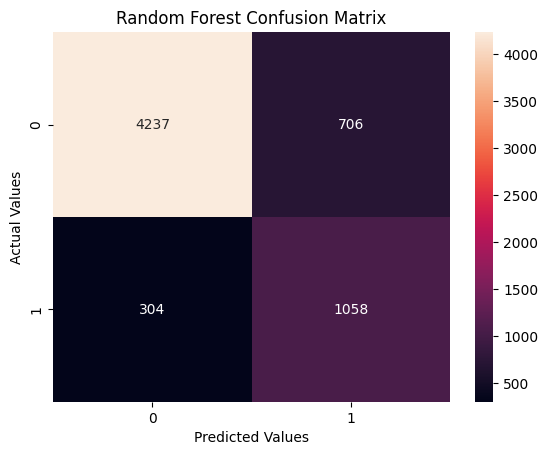

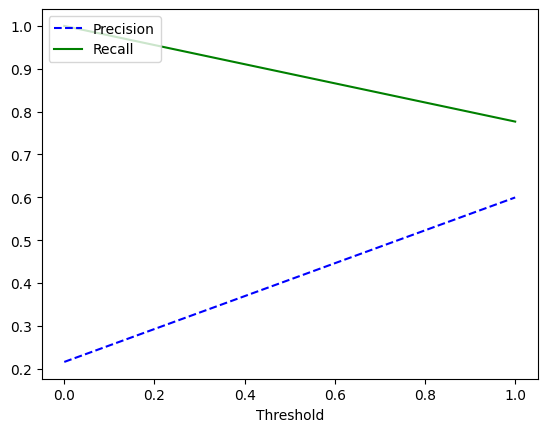

In [ ]:
# Passing the Random Forest Model after Hyperparameter Tuning
evalute_model("Random Forest" , random_search_rf.best_estimator_ , X_test , y_test)

12. Optimizing the Classification Threshold
- The model gives a probability, not a direct yes or no.
- We decide a cut-off point to turn it into a decision.
- We check different cut-off points and pick the best one.

XGboost Metrics:
Threshold: 0.9996131062507629
Accuracy : 0.92
Precision : 0.82
Recall : 0.79
F1 : 0.81

XGboost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



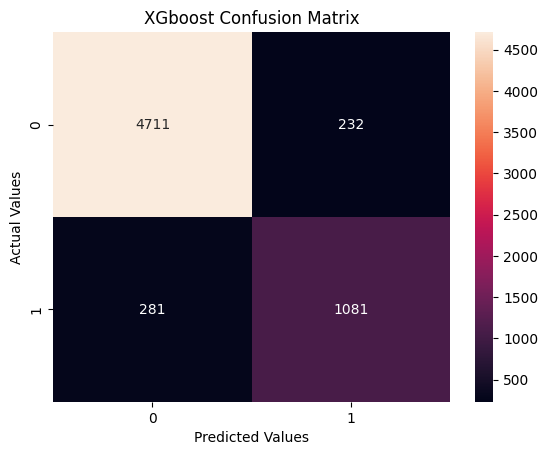

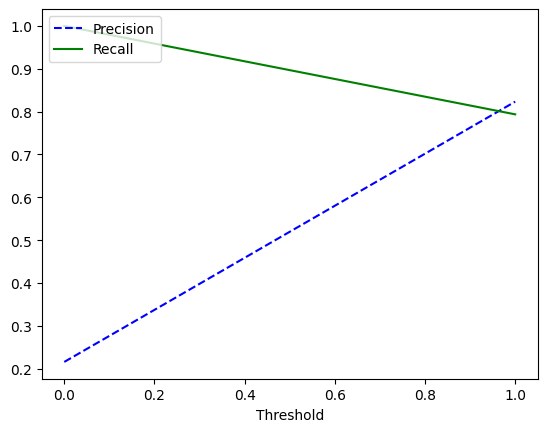

In [ ]:
# Get the prob of class 1 from XGboost
prob = xg_model.predict_proba(X_test)[:,1]
prob

# for Each threshold calculate Precision & Recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

# calculate F1 score for each threshold
f1 = 2 * (precisions - recalls) / (precisions + recalls + 1e-9)

# get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

# Evaluate the XGboost model using that threshold
evalute_model("XGboost" , xg_model , X_test , y_test ,  best_threshold)


13. Probability Calibration
- Sometimes a model's probability doesn't mean what it says.
- For example, 30% risk should truly mean a 30% chance.
- We check this with a calibration plot.
- We fix it if the probabilities are off.

In [ ]:
""""
Methods by which we fix the poorly calibrated model

1. platt scaling /sigmoid activation -> adjust the probability using sigmoid curve
2. isotonic reg -> learn a flexible mapping from old prob . - better prob .(None linear Calibration)
3. Temperature Scaling -> adjust the confidence of neural network predicion using one temperature
"""

'"\nMethods by which we fix the poorly calibrated model\n\n1. platt scaling /sigmoid activation -> adjust the probability using sigmoid curve\n2. isotonic reg -> learn a flexible mapping from old prob . - better prob .(None linear Calibration)\n3. Temperature Scaling -> adjust the confidence of neural network predicion using one temperature\n'

In [ ]:
# 1. calibrate the xgboost model
# 2. get the prob
# 3. Create the calibration curve
# 4. plt

In [ ]:
# 1. calibrate the xgboost model
from sklearn.calibration import CalibratedClassifierCV , calibration_curve

calibrated_model_xg = CalibratedClassifierCV(
    xg_model ,
    method = "sigmoid",
    cv= 5,
    n_jobs = -1
)

calibrated_model_xg.fit(X_train , y_train)

calibrated_model_rf = CalibratedClassifierCV(
    rf_model ,
    method = "sigmoid",
    cv= 5,
    n_jobs = -1
)
calibrated_model_rf.fit(X_train , y_train)


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(fill_value='Missing',
                                                                                                                  strategy='constant')),
                                                                                                   ('onehot',
                                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                                   Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])),
                                                 ('classifier',
                                                  RandomForestClassifier(class_weight='balanced',
                                                                         random_state=42))]),
                       n_jobs=-1)

In [ ]:
# 2. get the prob

uncalibrated_xg  =  xg_model.predict_proba(X_test)[:,1]
calibrated_xg =  calibrated_model_xg.predict_proba(X_test)[:,1]

uncalibrated_rf  =  rf_model.predict_proba(X_test)[:,1]
calibrated_rf =  calibrated_model_rf.predict_proba(X_test)[:,1]

print(uncalibrated_xg)
print(calibrated_xg)
print()
print()
print(uncalibrated_rf)
print(calibrated_rf)

[0.8254656  0.25111562 0.9782833  ... 0.48520026 0.07587515 0.05467961]
[0.75711989 0.04616006 0.94900388 ... 0.17461011 0.01793189 0.01380934]


[0.49 0.14 0.61 ... 0.44 0.   0.01]
[0.63586837 0.06394239 0.84012513 ... 0.55206537 0.0297537  0.03142046]


In [ ]:
# 3. Create the calibration curve

actual_call_xg , pred_call_xg = calibration_curve(y_test , calibrated_xg , n_bins =10)
actual_uncall_xg , pred_uncall_xg = calibration_curve(y_test , uncalibrated_xg , n_bins =10)

actual_call_rf , pred_call_rf = calibration_curve(y_test , calibrated_rf , n_bins =10)
actual_uncall_rf , pred_uncall_rf = calibration_curve(y_test , uncalibrated_rf , n_bins =10)

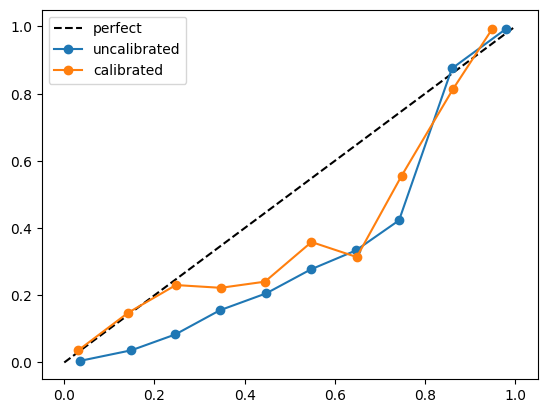

In [ ]:
# 4. plot for XGboost Model
plt.plot([0,1],[0,1], 'k--' , label= 'perfect')
plt.plot(
    pred_uncall_xg,
    actual_uncall_xg,
    'o-',
    label= "uncalibrated"
)
plt.plot(
    pred_call_xg,
    actual_call_xg,
    'o-',
    label= "calibrated"
)
plt.legend()

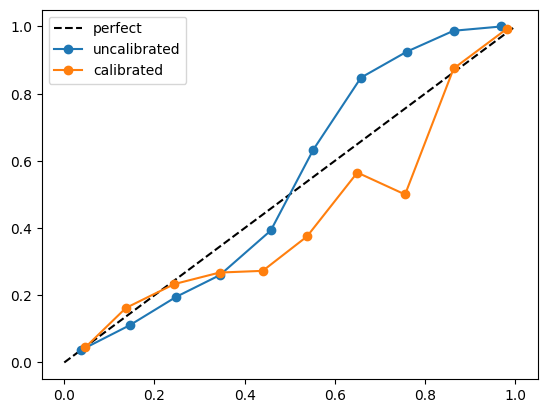

In [ ]:
# 4. plot for Random Forest Model
plt.plot([0,1],[0,1], 'k--' , label= 'perfect')
plt.plot(
    pred_uncall_rf,
    actual_uncall_rf,
    'o-',
    label= "uncalibrated"
)
plt.plot(
    pred_call_rf,
    actual_call_rf,
    'o-',
    label= "calibrated"
)
plt.legend()

14. SHAP Interpretation — Global & Local
- SHAP helps us understand why the model makes a decision.
- It is a way of explaining a "black box" model.

In [ ]:
!uv pip install shap

Using Python 3.13.16 environment at: /usr
Checked 1 package in 150ms


In [ ]:
import shap

# 2. Get the Trained XGboost & Random Forest Models out of the pipelines
xg_classifier = xg_model.named_steps['classifier']
rf_classifier = rf_model.named_steps['classifier']
-
# 3. Transform X_Test using the same preprocessing used for training .
X_test_transformed_xg = xg_model.named_steps['preprocessor'].transform(X_test)
X_test_transformed_rf = rf_model.named_steps['preprocessor'].transform(X_test)

# 4. Get feature names after the one-hot encoding , so plots are readable
feature_names_xg = xg_model.named_steps['preprocessor'].get_feature_names_out()
feature_names_rf = rf_model.named_steps['preprocessor'].get_feature_names_out()

# 5. Convert to a dataFrame  for cleaner SHAP plots
X_test_df_xg = pd.DataFrame(X_test_transformed_xg , columns=feature_names_xg)
X_test_df_rf = pd.DataFrame(X_test_transformed_rf , columns=feature_names_rf)

# 6.  Create SHAP explainer built for tree-based model
shap.initjs()
explainer_xg = shap.TreeExplainer(xg_classifier)
explainer_rf = shap.TreeExplainer(rf_classifier)

# 7. Calculate the SHAP values for every row in the test SET
shap_values_xg = explainer_xg.shap_values(X_test_df_xg)
shap_values_rf = explainer_rf.shap_values(X_test_df_rf)

SHAP TYPE 2 -> Global explanation
- This shows which features matter most overall.
- It also shows if a feature increases or decreases risk.

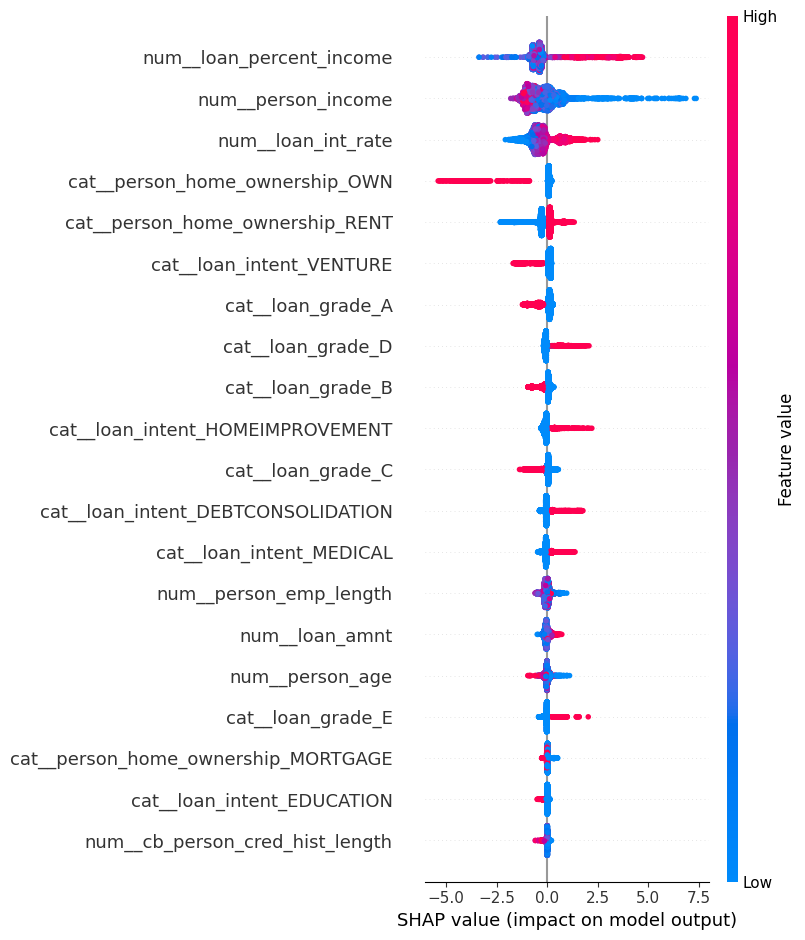

In [ ]:
shap.summary_plot(shap_values_xg , X_test_df_xg )

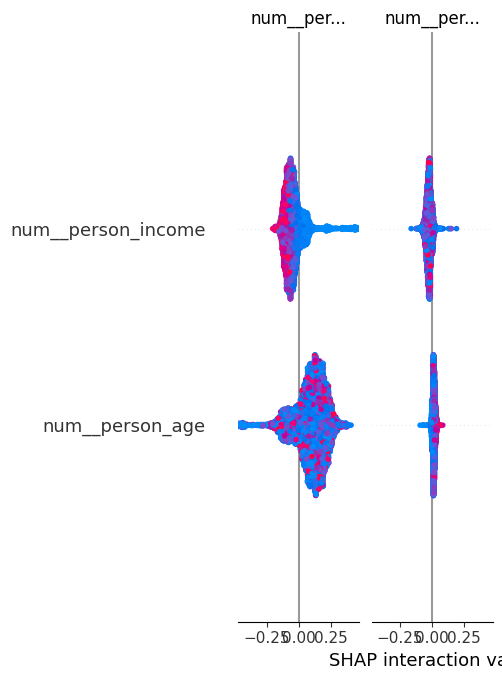

In [ ]:
shap.summary_plot(shap_values_rf , X_test_df_rf )

SHAPE TYPE 1 -> Local explanation
- This shows why one specific applicant got their score.
- It breaks the score down feature by feature.

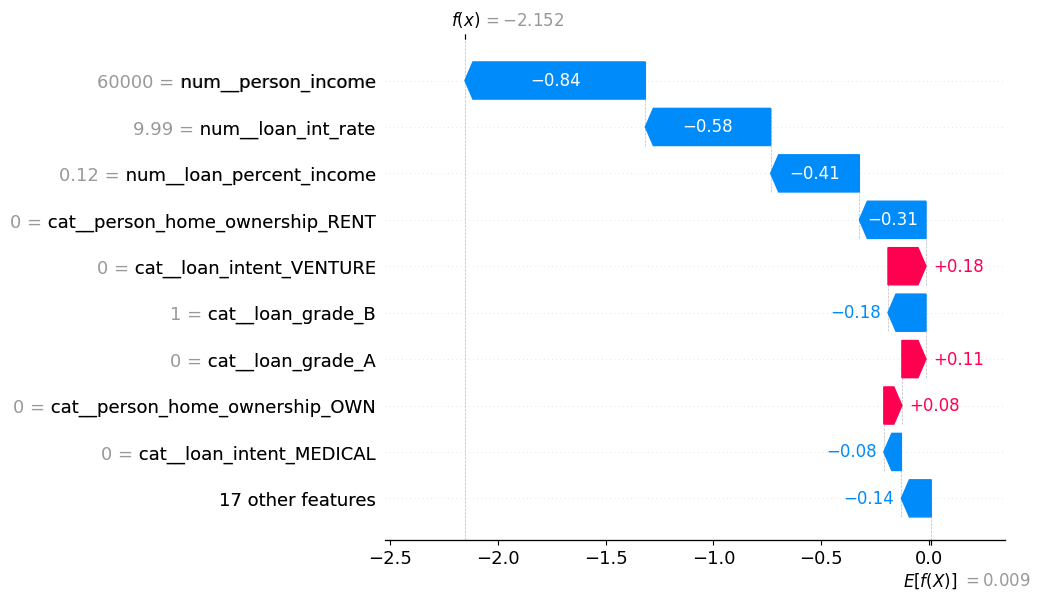

In [ ]:
# 1. Pick one row to explain , e.g the 5th applicant in the test set.
row_to_explain = 5

# 2. Draw  a waterfall plot showing how each feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values_xg[row_to_explain],
        base_values = explainer_xg.expected_value,
        data = X_test_df_xg.iloc[row_to_explain],
        feature_names = feature_names_xg
    )
)

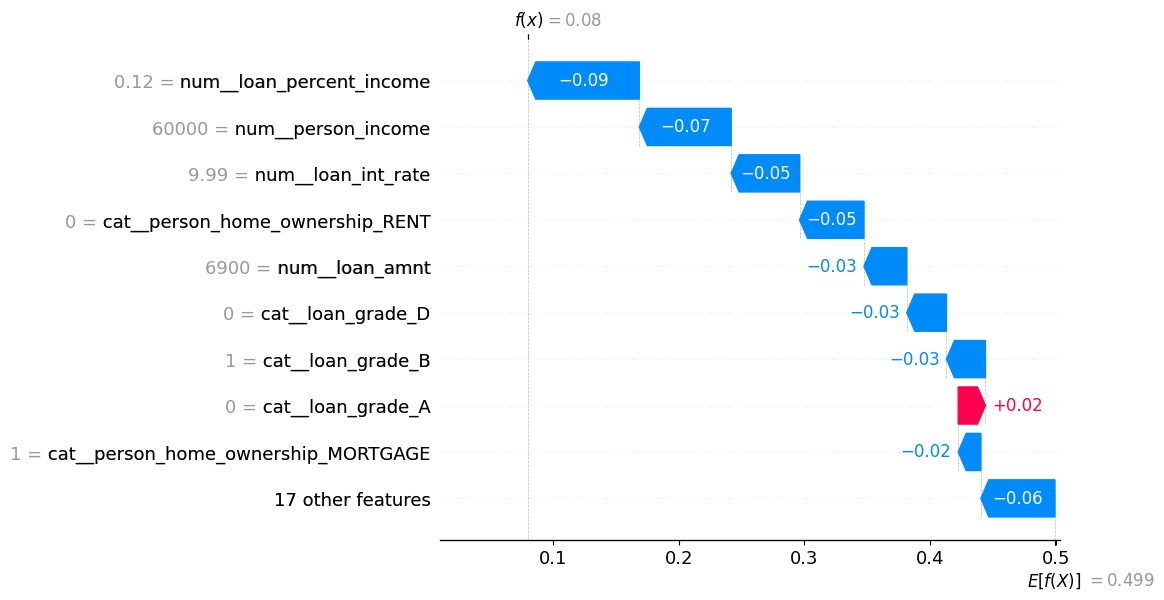

In [ ]:
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values_rf[row_to_explain][..., 1],
        base_values = explainer_rf.expected_value[1],
        data = X_test_df_rf.iloc[row_to_explain],
        feature_names = feature_names_rf
    )
)

15. Analyzing False Positives & False Negatives
- The model will not be perfect.
- False positives are safe people wrongly marked risky.
- False negatives are risky people wrongly marked safe.
- We study these cases to understand where the model struggles.

In [ ]:
# Get Predictions from the best performing XGboost model on the test set
y_pred_xg = random_search_xgb.predict(X_test)
y_pred_xg

array([0, 0, 1, ..., 1, 0, 0])

In [ ]:
y_pred_rf = random_search_rf.predict(X_test)
y_pred_rf

array([1, 1, 1, ..., 0, 0, 0])

In [ ]:
# Create a DataFrame to easily compare the actual & predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred_xg

In [ ]:
# Identify False Postive : Model predicted 1 but the actual was 0
false_pos = result_df[(result_df['actual'] == 0 ) & (result_df['predicted'] == 1)]

# Identify False Negetive : Model predicted 0 but the actual was 1
false_neg = result_df[(result_df['actual'] == 1 ) & (result_df['predicted'] == 0)]

In [ ]:
print(f"False Positives : {len(false_pos)}")
print(f"False Negatives : {len(false_neg)}")

False Positives : 256
False Negatives : 260


16. Save the Final Model
- Once we are happy with the model, we save it.
- We also save the settings it needs, like the chosen threshold.
- This saved file can now be used in a real application.

In [ ]:
from sklearn.metrics import precision_recall_curve

# 1. Get probabilities of the calibrated model , not the old xg_model
calibrated_model  = calibrated_model_xg.predict_proba(X_test)[:,1]

# 2. Re-run the same threshold search , now on the current probability scale
precisions , recalls , thresholds = precision_recall_curve(y_test , calibrated_model)
f1_score = 2 * (precisions * recalls ) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_score[:-1])]

print('best_threshold :' , best_threshold)

best_threshold : 0.7158444761787314


In [ ]:
import joblib

joblib.dump(calibrated_model , 'credit_risk_model.pkl')

['credit_risk_model.pkl']

In [ ]:
joblib.dump(best_threshold , 'best_threshold.pkl')

['best_threshold.pkl']

```markdown
## 17. Interactive Credit Risk Dashboard & Analytics (Plotly)
Now that we have trained and evaluated our models, let's build interactive, production-grade dashboards using Plotly. This will cover:
1. **Feature Distributions by Loan Status** (Interactive Box/Histogram plots)
2. **Model Performance Comparison** (ROC-AUC, F1, Accuracy, Precision, Recall)
3. **Interactive Confusion Matrices**
4. **Calibrated vs. Uncalibrated Probability Distributions**
```

In [81]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np

# Let's create an interactive multi-plot showing the key factors that correlate with loan default
# 1. Income vs Age colored by Loan Status
fig1 = px.scatter(
    df_copy,
    x='person_age',
    y='person_income',
    color='loan_status',
    color_continuous_scale=px.colors.diverging.Tealrose,
    labels={'person_age': 'Age', 'person_income': 'Annual Income', 'loan_status': 'Default Status'},
    title='Interactive Analysis: Annual Income vs Age by Default Status',
    log_y=True,
    hover_data=['person_emp_length', 'loan_intent']
)
fig1.update_layout(template='plotly_dark')
fig1.show()

In [82]:
# 2. Interactive Comparison of Model Performance Metrics across CV folds
metrics_data = {
    'Model': ['Logistic Regression', 'Logistic Regression', 'Logistic Regression', 'Logistic Regression', 'Logistic Regression',
              'XGBoost', 'XGBoost', 'XGBoost', 'XGBoost', 'XGBoost',
              'Random Forest', 'Random Forest', 'Random Forest', 'Random Forest', 'Random Forest'],
    'Metric': ['ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1'] * 3,
    'Score': [0.8705, 0.8116, 0.5448, 0.7781, 0.6408,
              0.9465, 0.9218, 0.8361, 0.7936, 0.8142,
              0.9278, 0.9323, 0.9703, 0.7080, 0.8186]
}

metrics_df = pd.DataFrame(metrics_data)

fig2 = px.bar(
    metrics_df,
    x='Metric',
    y='Score',
    color='Model',
    barmode='group',
    text_auto='.2f',
    title='Side-by-Side CV Performance Metrics Comparison',
    color_discrete_sequence=px.colors.qualitative.Pastel
)
fig2.update_layout(
    template='plotly_dark',
    yaxis_range=[0, 1.05],
    legend_title_text='Classification Models'
)
fig2.show()

In [83]:
# 3. Interactive Probability Calibration Curve for XGBoost & Random Forest
fig3 = go.Figure()

# Perfect Calibration Line
fig3.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1],
    line=dict(dash='dash', color='white'),
    name='Perfect Calibration'
))

# XGBoost Uncalibrated
fig3.add_trace(go.Scatter(
    x=pred_uncall_xg, y=actual_uncall_xg,
    mode='lines+markers',
    name='XGBoost (Uncalibrated)',
    line=dict(color='indianred')
))

# XGBoost Calibrated
fig3.add_trace(go.Scatter(
    x=pred_call_xg, y=actual_call_xg,
    mode='lines+markers',
    name='XGBoost (Calibrated)',
    line=dict(color='mediumseagreen')
))

# RF Calibrated
fig3.add_trace(go.Scatter(
    x=pred_call_rf, y=actual_call_rf,
    mode='lines+markers',
    name='Random Forest (Calibrated)',
    line=dict(color='dodgerblue')
))

fig3.update_layout(
    title='Interactive Probability Calibration Curves',
    xaxis_title='Mean Predicted Probability (Bins)',
    yaxis_title='Fraction of Positives',
    template='plotly_dark',
    legend_title_text='Models'
)
fig3.show()

In [84]:
# 4. Interactive Distribution of predicted probabilities showing where the threshold lies
fig4 = go.Figure()

fig4.add_trace(go.Violin(
    x=y_test,
    y=calibrated_xg,
    box_visible=True,
    meanline_visible=True,
    fillcolor='rgba(76, 175, 80, 0.4)',
    line_color='green',
    name='Calibrated XGBoost Probabilities'
))

# Add a horizontal indicator line for the chosen classification threshold
fig4.add_shape(
    type="line",
    x0=-0.5, y0=best_threshold, x1=1.5, y1=best_threshold,
    line=dict(color="Gold", width=3, dash="dashdot"),
    name="Best Threshold"
)

fig4.update_layout(
    title=f'Calibrated Probabilities Grouped by True Target (Best Threshold: {best_threshold:.4f})',
    xaxis_title='Actual Loan Status (0 = Repaid, 1 = Default)',
    yaxis_title='Predicted Default Probability',
    template='plotly_dark'
)
fig4.show()

In [85]:
# 5. Interactive 3D Scatter Plot for Credit Risk Landscapes
# This analyzes the 3D interaction between Age, Income, and Loan Amount, with point sizing based on the default probability.

# Create a subset for visualization to keep performance optimal and clean
viz_df = X_test.copy()
viz_df['calibrated_prob'] = calibrated_xg
viz_df['actual_status'] = y_test.map({0: 'Repaid', 1: 'Defaulted'})

fig5 = go.Figure(data=[go.Scatter3d(
    x=viz_df['person_age'],
    y=viz_df['person_income'],
    z=viz_df['loan_amnt'],
    mode='markers',
    marker=dict(
        size=4 + (viz_df['calibrated_prob'] * 12),  # Higher probability = larger marker
        color=viz_df['calibrated_prob'],           # Color mapping to calibrated probability
        colorscale='Viridis',
        opacity=0.8,
        colorbar=dict(title='Default Probability'),
        line=dict(width=0.5, color='rgb(50,50,50)')
    ),
    text=viz_df.apply(lambda r: f"Age: {r['person_age']}<br>Income: ${r['person_income']:,}<br>Loan: ${r['loan_amnt']:,}<br>Prob: {r['calibrated_prob']:.2%}", axis=1),
    hoverinfo='text'
)])

fig5.update_layout(
    title='3D Credit Risk Landscape: Age vs. Income vs. Loan Amount',
    scene=dict(
        xaxis=dict(title='Age (Years)', backgroundcolor="rgb(20, 20, 20)", gridcolor="gray", showbackground=True),
        yaxis=dict(title='Annual Income ($)', backgroundcolor="rgb(20, 20, 20)", gridcolor="gray", showbackground=True, type='log'),
        zaxis=dict(title='Loan Amount ($)', backgroundcolor="rgb(20, 20, 20)", gridcolor="gray", showbackground=True)
    ),
    width=900,
    height=750,
    template='plotly_dark'
)

fig5.show()

In [86]:
# 6. Additional Interactive 3D Scatter Plot: The Debt-Burden Risk Terrain
# This visualizes the intersection of Age, Loan Interest Rate, and Loan-to-Income Percent,
# allowing us to see how the model isolates risky applicants on crucial policy limits.

fig6 = go.Figure(data=[go.Scatter3d(
    x=viz_df['person_age'],
    y=viz_df['loan_int_rate'],
    z=viz_df['loan_percent_income'],
    mode='markers',
    marker=dict(
        size=5,
        color=viz_df['calibrated_prob'], # Colormap represents default risk probability
        colorscale='Hot',
        showscale=True,
        colorbar=dict(title='Default Probability', x=0.85),
        opacity=0.7,
        line=dict(width=0.2, color='white')
    ),
    text=viz_df.apply(lambda r: f"Age: {r['person_age']}<br>Interest Rate: {r['loan_int_rate']}%<br>Debt-to-Income: {r['loan_percent_income']:.1%}<br>Risk: {r['calibrated_prob']:.2%}", axis=1),
    hoverinfo='text'
)])

# Configure scene lighting, camera, and dark themed background
fig6.update_layout(
    title='3D Risk Terrain: Age vs. Interest Rate vs. Debt-to-Income Percent',
    scene=dict(
        xaxis=dict(title='Age (Years)', backgroundcolor="rgb(15, 15, 15)", gridcolor="rgb(60, 60, 60)", showbackground=True),
        yaxis=dict(title='Interest Rate (%)', backgroundcolor="rgb(15, 15, 15)", gridcolor="rgb(60, 60, 60)", showbackground=True),
        zaxis=dict(title='Debt-to-Income Ratio', backgroundcolor="rgb(15, 15, 15)", gridcolor="rgb(60, 60, 60)", showbackground=True)
    ),
    width=900,
    height=750,
    template='plotly_dark'
)

fig6.show()